<img src="../res/logo.jpg" alt="Volcanicus" width="50%">

# Baseline and anomalies

A residual of 0.1 doesn't mean the same on every volcano: some sit on a warmer or noisier background than others, and even within a volcano each direction can have its own (a slope facing the sun, the sea). To compare scenes across volcanoes, each one needs to be measured against **its own usual state**.

This notebook covers `scenes_baseline()` and `scenes_anomaly()`. See [scenes.ipynb](scenes.ipynb) and [rays.ipynb](rays.ipynb) first.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import volcanicus
from volcanicus.constants import DIRECTION_ORDER


def show_grid(ax, frame_row, title, **kwargs):
    """Draw one scene-shaped row as a direction x distance image."""
    grid = frame_row.unstack("distance").reindex(
        index=list(DIRECTION_ORDER), columns=distances
    )
    im = ax.imshow(grid.to_numpy(dtype=float), aspect="auto", **kwargs)
    ax.set_yticks(range(len(DIRECTION_ORDER)), DIRECTION_ORDER)
    ax.set_xticks(range(0, len(distances), 5), distances[::5])
    ax.set_title(title)
    ax.figure.colorbar(im, ax=ax)


# corrupted rays would leak into the baseline: mask them first
volcano = volcanicus.datasets.load("etna").mask_rays()
distances = list(volcano.scenes_median.columns)
volcano

dates,100
missing,896
registers,792


## The baseline

`scenes_baseline()` describes every `(direction, distance)` cell over all the volcano's scenes with two robust statistics:

- `center`: the median, the cell's usual value.
- `scale`: `1.4826 * MAD` (median absolute deviation), the cell's usual spread. The factor makes it match the standard deviation for normally distributed data, but unlike the standard deviation a few extreme scenes barely move it.

Both come out with the same columns as `to_scenes()`.

In [2]:
baseline = volcano.scenes_baseline()
baseline.iloc[:, :5]

direction         N                                        
distance        15m       45m       75m      105m      135m
center     0.149400  0.157500  0.097200  0.088200  0.059950
scale      0.181915  0.183546  0.133137  0.093997  0.089178

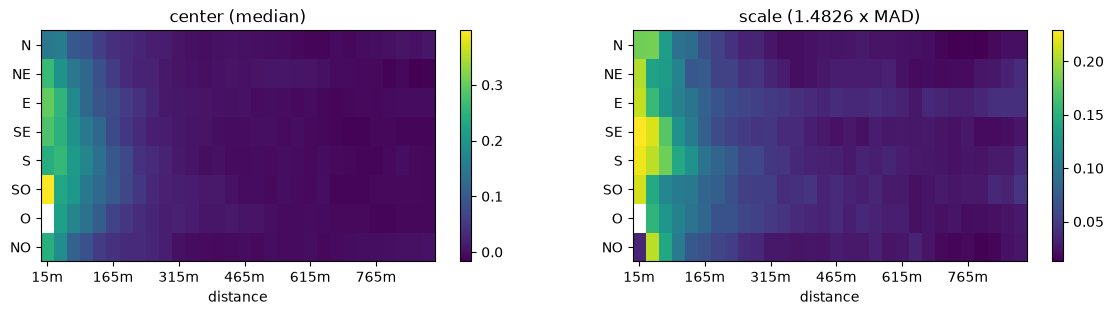

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
show_grid(axes[0], baseline.loc["center"], "center (median)")
show_grid(axes[1], baseline.loc["scale"], "scale (1.4826 x MAD)")
for ax in axes:
    ax.set_xlabel("distance")

Etna's usual state is warmer and more variable near the vent, as expected, and not quite the same in every direction.

## Anomalies

`scenes_anomaly()` expresses every cell of every scene as a robust z-score, `(value - center) / scale`: how many usual deviations it sits above (positive) or below (negative) that cell's usual value. The result has exactly the shape of `to_scenes()`.

`volcano.plot.scene(date, anomaly=True)` draws a scene's anomalies (red: hotter than usual, blue: colder). Here is Etna's hottest scene, raw and as anomalies:

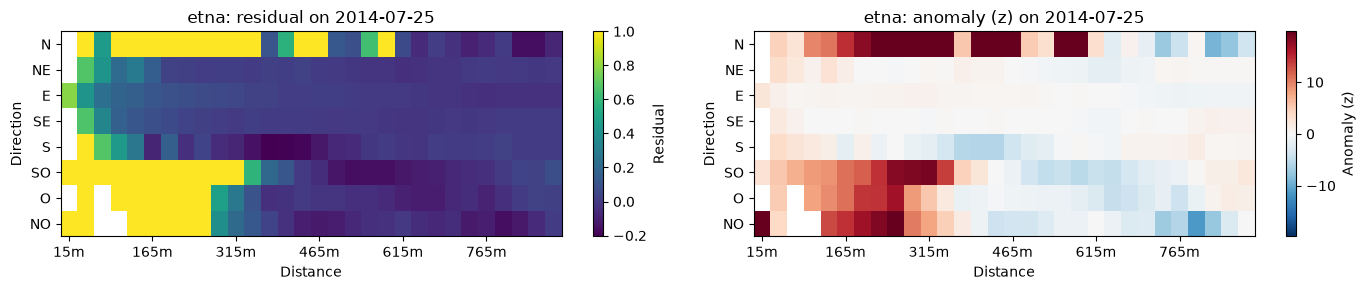

In [4]:
anomaly = volcano.scenes_anomaly()
date = volcano.scenes_descriptors()["peak"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
volcano.plot.scene(date, ax=axes[0])
volcano.plot.scene(date, anomaly=True, ax=axes[1])
fig.tight_layout()

The raw scene says *where it's hot*; the anomaly says *where it's unusually hot for that spot*. Raw, the near field looks hot all around the vent. As anomalies, the E and SE near field turns out to be ordinary for Etna (it usually runs that warm), while the N and SO to NO sides sit far above their usual values out to about 400 m. Keep saturation in mind: where the raw image is at 1.0, the anomaly is a floor too.

## Comparable across volcanoes

Raw near-field residuals live on very different scales from one volcano to another; anomalies put them on the same one. Comparing three volcanoes with different thermal regimes, using each scene's median value within 300 m:

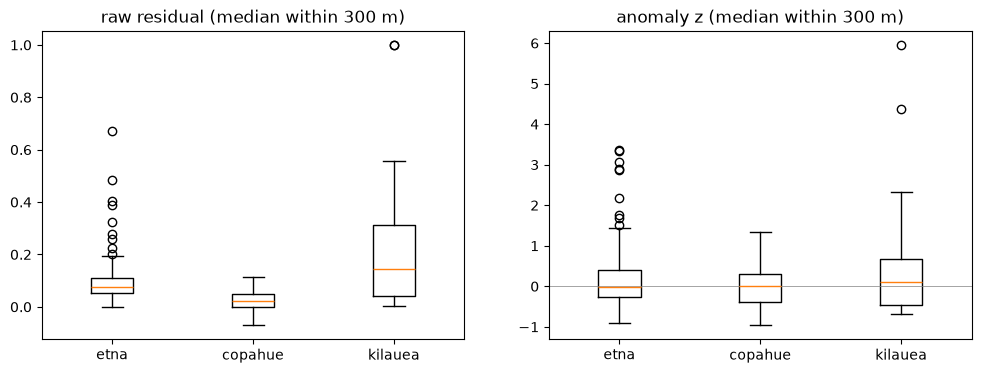

In [5]:
names = ["etna", "copahue", "kilauea"]
near = [d for d in distances if float(d.removesuffix("m")) <= 300]

raw, z = {}, {}
for name in names:
    v = volcanicus.datasets.load(name).mask_rays()
    scenes, anomalies = v.to_scenes(), v.scenes_anomaly()
    cols = [(d, r) for d in DIRECTION_ORDER for r in near]
    raw[name] = scenes[cols].median(axis=1)
    z[name] = anomalies[cols].median(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([raw[n].dropna() for n in names], tick_labels=names)
axes[0].set_title("raw residual (median within 300 m)")
axes[1].boxplot([z[n].dropna() for n in names], tick_labels=names)
axes[1].set_title("anomaly z (median within 300 m)")
axes[1].axhline(0, c="gray", lw=0.5)

On the raw scale, Kilauea's values are several times larger and more spread out than Copahue's; as anomalies all three are centered on 0 and their spikes can be compared directly. The flip side: anomalies are **relative**. A volcano that is hot all the time doesn't look anomalous, by design.

## ⚠️ Caveats

**"Usual" isn't "quiet".** The baseline is the median over *all* the scenes. For a volcano active in most of them (a lava lake, a persistently open vent), the usual state *is* the active one, and anomalies measure departures from it: a lull shows up as a negative anomaly.

**Saturated cells have no anomaly.** Where a cell is at the saturation level in most scenes, its MAD is 0 and the scale is `NaN`: nothing can be said about how unusual a capped value is. Nyiragongo's lava lake is the clearest case. Of its cells without a scale, those with plenty of scenes are saturated more than half the time; the rest simply have too few scenes (next caveat):

In [6]:
nyiragongo = volcanicus.datasets.load("nyiragongo").mask_rays()
scale = nyiragongo.scenes_baseline().loc["scale"]
cells = nyiragongo.to_scenes()[scale[scale.isna()].index]
pd.DataFrame(
    {
        "n_scenes": cells.count(),
        "median": cells.median(),
        "fraction_saturated": (cells == 1.0).sum() / cells.count(),
    }
).round(2)

n_scenes  median  fraction_saturated
direction distance                                      
NE        15m              3    0.16                0.00
E         15m              0     NaN                 NaN
S         15m             71    1.00                0.69
SO        15m             67    1.00                0.54
          75m             68    1.00                0.56
O         15m              1    0.69                0.00
          45m             76    1.00                0.51

**Few scenes, no baseline.** Cells with fewer than `min_scenes` (default 10) values get a `NaN` baseline. A volcano with only a handful of scenes gets no anomalies at all:

In [7]:
veniaminof = volcanicus.datasets.load("veniaminof")
print(len(veniaminof.to_scenes()), "scene(s)")
veniaminof.scenes_anomaly().isna().all().all()

1 scene(s)


np.True_

**Mask corrupted rays first.** The median and MAD are robust, so a corrupted ray barely moves the baseline, but that ray's own anomaly is absurd. On Kadovar, 2018-05-27:

In [8]:
kadovar = volcanicus.datasets.load("kadovar")
bad_date = pd.Timestamp("2018-05-27")
pd.DataFrame(
    {
        "raw": kadovar.scenes_anomaly().loc[bad_date, "NO"],
        "masked": kadovar.mask_rays().scenes_anomaly().loc[bad_date, "NO"],
    }
).reindex(distances).iloc[:6].round(1)

,raw,masked
distance,,
15m,NaN,NaN
45m,-10385.2,NaN
75m,-11283.4,NaN
105m,-11216.8,NaN
135m,-15733.2,NaN
165m,NaN,NaN


## Next steps

- [episodes.ipynb](episodes.ipynb) uses these anomalies to find periods of unusual activity.
- [rays.ipynb](rays.ipynb) for `mask_rays()`.